In [1]:
import sys, pickle, warnings
from pathlib import Path
import numpy as np
import torch
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
from PIL import Image

In [ ]:
# SETUP
ROOT = Path.cwd().parent
DATA = ROOT / "data"
sys.path.insert(0, str(ROOT / "ConceptBottleneck"))
warnings.filterwarnings("ignore", message="source code of class")

# Open Dataset
test_data = pickle.load(open(DATA / "CUB_processed/test.pkl", "rb"))

# Setup CUDA device
device = "cuda" if torch.cuda.is_available() else "cpu"
print(device, torch.cuda.get_device_name(0) if device == "cuda" else "")

# Name of the concepts
concepts_names = open(DATA / "CUB_200_2011/attributes/attributes.txt").read().splitlines()
print(f"Concpets example: {concepts_names[::15][:5]}")

# Name of the classes
classes = open(DATA / "CUB_200_2011/classes.txt").read().splitlines()
print(f"Classes example: {classes[::15][:5]}")


# The 112 of 312 CUB attributes used by the paper, 0-based (from CUB/generate_new_data.py).
SELECTED_ATTRIBUTES = [
    1, 4, 6, 7, 10, 14, 15, 20, 21, 23, 25, 29, 30, 35, 36, 38, 40, 44, 45, 50, 51, 53, 54, 56, 57, 59, 63, 64,
    69, 70, 72, 75, 80, 84, 90, 91, 93, 99, 101, 106, 110, 111, 116, 117, 119, 125, 126, 131, 132, 134, 145, 149,
    151, 152, 153, 157, 158, 163, 164, 168, 172, 178, 179, 181, 183, 187, 188, 193, 194, 196, 198, 202, 203, 208,
    209, 211, 212, 213, 218, 220, 221, 225, 235, 236, 238, 239, 240, 242, 243, 244, 249, 253, 254, 259, 260, 262,
    268, 274, 277, 283, 289, 292, 293, 294, 298, 299, 304, 305, 308, 309, 310, 311,
]


cuda NVIDIA GeForce RTX 4070 Laptop GPU
Concpets example: ['1 has_bill_shape::curved_(up_or_down)', '16 has_wing_color::yellow', '31 has_upperparts_color::yellow', '46 has_underparts_color::yellow', '61 has_back_color::iridescent']
Classes example: ['1 001.Black_footed_Albatross', '16 016.Painted_Bunting', '31 031.Black_billed_Cuckoo', '46 046.Gadwall', '61 061.Heermann_Gull']


Class: 001.Black_footed_Albatross
Concepts: ['has_bill_shape::hooked_seabird', 'has_underparts_color::grey', 'has_breast_pattern::solid', 'has_eye_color::black', 'has_bill_length::about_the_same_as_head', 'has_size::medium_(9_-_16_in)', 'has_back_pattern::solid', 'has_tail_pattern::solid', 'has_belly_pattern::solid']


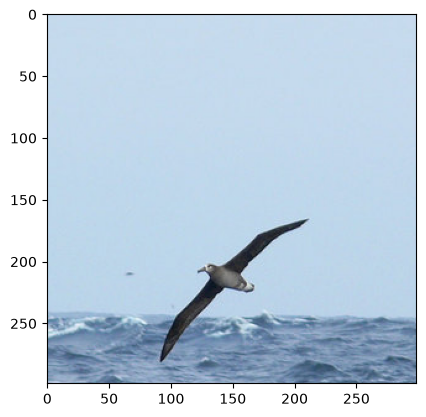

In [3]:
def get_image_from_index(index, dataset=test_data):
    """
    Get the image from the test dataset given an index.
    """
    img_path = DATA / "CUB_200_2011" / dataset[index]["img_path"].split("CUB_200_2011/")[-1]
    img = Image.open(img_path).convert("RGB")
    return img

def apply_transform_to_image(img, transform):
    """
    Apply the transformation to the image.
    """
    if transform == "test":
        # Test Transformations to image
        resol = 299
        test_transform = transforms.Compose([
            transforms.CenterCrop(resol),
            transforms.ToTensor(), #implicitly divides by 255
            transforms.Normalize(mean = [0.5, 0.5, 0.5], std = [2, 2, 2])
        ])
        
        return test_transform(img)
    
    else:
        raise ValueError(f"Unknown transform: {transform}")
    
def visualise_image(img, transformed=False):
    """
    Visualize the image.
    """

    if transformed:
        visual_img = img * 2 + 0.5
        visual_img = visual_img.permute(1, 2, 0)
        plt.imshow(visual_img)
    else:
        plt.imshow(img)


def get_class_from_index(index, dataset=test_data):
    """
    Get the class from the test dataset given an index.
    """
    return classes[dataset[index]["class_label"]].strip().split(" ")[1]

def get_concepts_from_index(index, dataset=test_data):
    """
    Get the names of the concepts labelled present for a test image, given its index.
    """
    selected_concept_names = [concepts_names[i] for i in SELECTED_ATTRIBUTES]
    labels = dataset[index]["attribute_label"]

    present_concepts = []
    for name, label in zip(selected_concept_names, labels):
        if label == 1:
            present_concepts.append(name.split(" ")[1])
    
    return present_concepts



img = get_image_from_index(0)
transformed_img = apply_transform_to_image(img, "test")
visualise_image(transformed_img, transformed=True)



class_name = get_class_from_index(0)
concepts = get_concepts_from_index(0)

print(f"Class: {class_name}")
print(f"Concepts: {concepts}")

In [4]:
# Load models
joint_model_path = DATA / "models" / "Joint0.01Model__Seed1" / "best_model_1.pth"
joint_model = torch.load(joint_model_path, map_location=torch.device(device), weights_only=False)
joint_model.eval()

concept_model_path = DATA / "models" / "ConceptModel__Seed1" / "best_model_1.pth"
concept_model = torch.load(concept_model_path, map_location=torch.device(device), weights_only=False)
concept_model.eval()

independent_head_path = DATA / "models" / "IndependentModel_WithVal___Seed1" / "best_model_1.pth"
independent_head = torch.load(independent_head_path, map_location=torch.device(device), weights_only=False)
independent_head.eval()

sequential_head_path = DATA / "models" / "SequentialModel_WithVal__Seed1" / "best_model_1.pth"
sequential_head = torch.load(sequential_head_path, map_location=torch.device(device), weights_only=False)
sequential_head.eval()

def run_model(model_name, img):
    """
    Run the model on the image and return the predicted class and concepts.
    """

    # Add batch dimension and move to device
    img = img.unsqueeze(0).to(device)

    # Run the model
    with torch.no_grad():
        if model_name == "joint":
            out = joint_model(img)
            raw_concepts = torch.concat(out[1:], dim=1)
            class_scores = out[0]

        elif model_name == "independent":
            raw_concepts = torch.cat(concept_model(img), dim=1)
            class_scores = independent_head(torch.sigmoid(raw_concepts))

        elif model_name == "sequential":
            raw_concepts = torch.cat(concept_model(img), dim=1)      
            class_scores = sequential_head(raw_concepts)

        else:
            raise ValueError(f"Unknown model name: {model_name}")
        
    class_scores = torch.softmax(class_scores, dim=1)
    return class_scores, raw_concepts



def get_top_k_class_pred(class_scores, top_k, classes):
    """
    Get the top-k predictions labels and confidence
    """
    
    top_k_scores, top_k_idxs = torch.topk(class_scores, top_k)
    top_k_predictions = {}

    for i in range(top_k):
        class_index = top_k_idxs[0][i].item()
        class_score = top_k_scores[0][i].item()
        class_name = classes[class_index]

        top_k_predictions[class_name] = class_score

    return top_k_predictions


def get_found_concepts(raw_concepts, index, dataset=test_data, verbose=True):
    """
    Compare the predicted concepts to the labels and return the number that match.
    """
    concept_labels = torch.tensor(dataset[index]["attribute_label"], device=device).bool()
    concepts_prob = torch.sigmoid(raw_concepts)[0]
    predicted_concepts = concepts_prob > 0.5

    matches = (predicted_concepts == concept_labels).sum().item()

    if verbose:
        print(f"    Matching concepts: {matches}/{len(concept_labels)}")
        print(f"    Predicted present: {predicted_concepts.sum().item()}, truly present: {concept_labels.sum().item()}")

    return matches


In [5]:
class_scores, raw_concepts = run_model("joint", transformed_img)

get_found_concepts(raw_concepts, 0)
get_top_k_class_pred(class_scores, 5, classes)

    Matching concepts: 103/112
    Predicted present: 14, truly present: 9


{'72 072.Pomarine_Jaeger': 0.47297611832618713,
 '44 044.Frigatebird': 0.17524652183055878,
 '71 071.Long_tailed_Jaeger': 0.11867637932300568,
 '100 100.Brown_Pelican': 0.08597178757190704,
 '3 003.Sooty_Albatross': 0.03618929907679558}

In [6]:
def compare_models(index, top_k=5, show_img=False):
    # Get Image, transform it
    img = get_image_from_index(index, test_data)
    transformed_img = apply_transform_to_image(img, "test")
    if show_img:
        visualise_image(transformed_img, transformed=True)

    true_class = get_class_from_index(index, test_data)
    print(f"True Class: {true_class}")

    models = ["joint", "independent", "sequential"]

    for model in models:
        print(f"Current Model: {model}")
        class_scores, raw_concepts = run_model(model, transformed_img)

        top_k_class_predictions = get_top_k_class_pred(class_scores, top_k, classes)
        print(f"    Top {top_k} predictions:{top_k_class_predictions}")

        concept_matches = get_found_concepts(raw_concepts, index, test_data)
        





True Class: 001.Black_footed_Albatross
Current Model: joint
    Top 5 predictions:{'72 072.Pomarine_Jaeger': 0.47297611832618713, '44 044.Frigatebird': 0.17524652183055878, '71 071.Long_tailed_Jaeger': 0.11867637932300568, '100 100.Brown_Pelican': 0.08597178757190704, '3 003.Sooty_Albatross': 0.03618929907679558}
    Matching concepts: 103/112
    Predicted present: 14, truly present: 9
Current Model: independent
    Top 5 predictions:{'1 001.Black_footed_Albatross': 0.07106846570968628, '3 003.Sooty_Albatross': 0.03160097077488899, '71 071.Long_tailed_Jaeger': 0.022050561383366585, '23 023.Brandt_Cormorant': 0.01625879853963852, '72 072.Pomarine_Jaeger': 0.014402149245142937}
    Matching concepts: 111/112
    Predicted present: 8, truly present: 9
Current Model: sequential
    Top 5 predictions:{'1 001.Black_footed_Albatross': 0.10724835842847824, '61 061.Heermann_Gull': 0.04663429409265518, '24 024.Red_faced_Cormorant': 0.03787790983915329, '72 072.Pomarine_Jaeger': 0.02791755832731

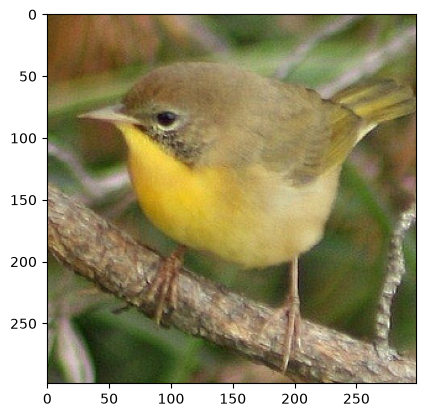

In [7]:
for idx in range(0, len(test_data), len(test_data) // 5):
    compare_models(idx, 5, True)
    print()

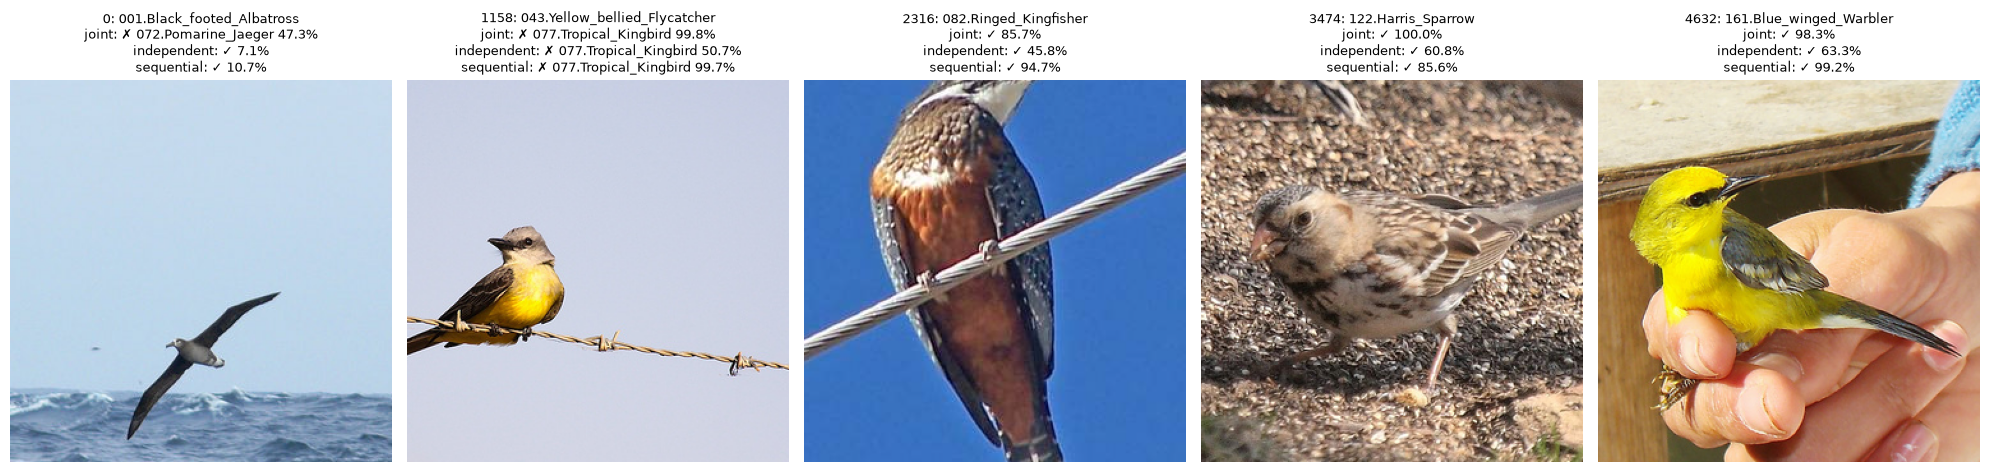

In [8]:
def show_image_grid(indices, dataset=test_data):
    """
    Show the images in a row, titled with the true class and each model's prediction.
    """
    models = ["joint", "independent", "sequential"]
    fig, axes = plt.subplots(1, len(indices), figsize=(4 * len(indices), 5.5), squeeze=False)

    for ax, index in zip(axes[0], indices):
        # Get Image, transform it
        img = get_image_from_index(index, dataset)
        transformed_img = apply_transform_to_image(img, "test")

        # Draw on this subplot
        plt.sca(ax)
        visualise_image(transformed_img, transformed=True)
        ax.axis("off")

        title = [f"{index}: {get_class_from_index(index, dataset)}"]

        for model in models:
            class_scores, raw_concepts = run_model(model, transformed_img)
            predicted_class = class_scores.argmax(dim=1).item()
            confidence = class_scores.max().item()

            if predicted_class == dataset[index]["class_label"]:
                title.append(f"{model}: ✓ {confidence:.1%}")
            else:
                predicted_name = classes[predicted_class].strip().split(" ")[1]
                title.append(f"{model}: ✗ {predicted_name} {confidence:.1%}")

        ax.set_title("\n".join(title), fontsize=9)

    plt.tight_layout()
    plt.show()


indices = list(range(0, len(test_data), len(test_data) // 5))[:5]
show_image_grid(indices)

In [9]:
def evaluate_models(indices, models, dataset=test_data):
    results = {model: {"correct": 0, "concept_matches": 0} for model in models}

    for i, idx in enumerate(indices):
        img = get_image_from_index(idx, dataset)
        transformed_img = apply_transform_to_image(img, "test")

        for model in models:
            class_scores, raw_concepts = run_model(model, transformed_img)

            if class_scores.argmax(dim=1).item() == dataset[idx]["class_label"]:
                results[model]["correct"] += 1

            found_concepts = get_found_concepts(raw_concepts, idx, dataset, verbose=False)
            results[model]["concept_matches"] += found_concepts

        if i % 100 == 0:
            print(f"Progress: {i} / {len(indices)}")

    return results

def calculate_model_accuracy(indices, models, results):
    accuracies = {model: {"class_acc": 0, "concept_acc": 0} for model in models}
    n =  len(indices)
    
    for model in models:
        correct_classes = results[model]["correct"]
        concept_matches = results[model]["concept_matches"]

        class_acc = correct_classes / n
        concept_acc = concept_matches / (n * 112)

        accuracies[model]["class_acc"] += class_acc
        accuracies[model]["concept_acc"] += concept_acc

    return accuracies
            

In [10]:
indices = range(0, len(test_data), 10)
models = ["joint", "independent", "sequential"]

results = evaluate_models(indices, models, test_data)
accuracies = calculate_model_accuracy(indices, models, results )

for model in models:
    print(f"{model}: class {accuracies[model]['class_acc']:.1%}, concepts {accuracies[model]['concept_acc']:.1%}")

Progress: 0 / 580
Progress: 100 / 580
Progress: 200 / 580
Progress: 300 / 580
Progress: 400 / 580
Progress: 500 / 580
joint: class 79.3%, concepts 97.0%
independent: class 76.0%, concepts 96.7%
sequential: class 75.5%, concepts 96.7%
